In [1]:
%load_ext cuml.accel

# Credit Card Fraud Detection

## Project overview

Credit-card fraud detection is a **binary classification problem with a highly imbalanced target**. Most transactions are legitimate (`Class = 0`), while only a small fraction are fraudulent (`Class = 1`). A model can therefore achieve high accuracy by predicting the majority class and still miss many fraud cases.

This notebook explores the data, preserves the original transaction-level EDA, and compares multiple ways to train models under class imbalance. It is written to be readable as both a GitHub project and an interview-preparation reference.

### Questions this project investigates

1. What does the class imbalance look like, and what patterns are visible in the transaction data?
2. How does a Logistic Regression baseline behave?
3. How does a standard Random Forest trained on the original training distribution compare with `class_weight="balanced_subsample"`?
4. What changes when default SMOTE is applied to the training data?
5. Which metrics are most useful when fraud is the minority class?

> **Reproducibility note:** The original EDA figures are retained from your notebook so your charts remain visible. Run the notebook from top to bottom to regenerate all figures and model results using the raw dataset loaded by this version.

## Notebook roadmap

1. Load the dataset and inspect its quality
2. Exploratory data analysis (EDA)
3. Feature engineering and a stratified train/test split
4. Logistic Regression baseline
5. Random Forest on the original imbalanced training data
6. Random Forest with `balanced_subsample`
7. Random Forest with default SMOTE
8. Compare models and inspect precision–recall behaviour
9. Interview explanation, limitations, and possible next steps

### How to run

Install the packages listed in `requirements.txt`, then run every cell in order. The notebook first looks for `data/creditcard.csv`; if it is not found, it uses KaggleHub to download the public `mlg-ulb/creditcardfraud` dataset. The dataset itself is not included in this repository.

## 1. Imports and setup

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

## 2. Load the dataset

In [3]:
# Prefer a local copy (useful when running the repository offline).
local_data_path = Path("data") / "creditcard.csv"

if local_data_path.exists():
    data_path = local_data_path
else:
    try:
        import kagglehub
    except ImportError as exc:
        raise ImportError(
            "Dataset not found at data/creditcard.csv. Install requirements.txt "
            "to enable KaggleHub download, or place creditcard.csv in the data/ folder."
        ) from exc

    dataset_dir = Path(kagglehub.dataset_download("mlg-ulb/creditcardfraud"))
    if dataset_dir.is_file() and dataset_dir.name.lower() == "creditcard.csv":
        data_path = dataset_dir
    else:
        candidates = list(dataset_dir.rglob("creditcard.csv"))
        if not candidates:
            raise FileNotFoundError(
                f"Could not find creditcard.csv inside downloaded folder: {dataset_dir}"
            )
        data_path = candidates[0]

print(f"Loading dataset from: {data_path}")
df = pd.read_csv(data_path)
print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]} columns.")

Using Colab cache for faster access to the 'creditcardfraud' dataset.
Loading dataset from: /kaggle/input/creditcardfraud/creditcard.csv
Loaded 284,807 rows and 31 columns.


### Dataset context

The commonly used `mlg-ulb/creditcardfraud` dataset contains transactions made by European cardholders. The anonymized `V1`–`V28` features are principal-component transformed features. `Time` represents elapsed time between transactions, `Amount` is the transaction amount, and `Class` is the target (`0` for legitimate and `1` for fraud).

The transaction amount is often strongly right-skewed, so this project also creates `Amount_log = log(1 + Amount)` for modeling.

### Initial inspection

In [4]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [5]:
df.shape

(284807, 31)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [7]:
df["Class"].value_counts().sort_index()

,count
Class,
0,284315
1,492


In [8]:

df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [9]:
missing_values = df.isnull().sum()
missing_values

,0
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


In [10]:
# Validate the target before training.
assert "Class" in df.columns, "The dataset must contain the target column 'Class'."
assert df["Class"].isin([0, 1]).all(), "Expected binary labels 0 (legitimate) and 1 (fraud)."

class_counts = df["Class"].value_counts().sort_index()
fraud_percentage = 100 * class_counts.get(1, 0) / len(df)
print(f"Legitimate transactions (Class 0): {class_counts.get(0, 0):,}")
print(f"Fraudulent transactions (Class 1): {class_counts.get(1, 0):,}")
print(f"Fraud share: {fraud_percentage:.4f}%")

Legitimate transactions (Class 0): 284,315
Fraudulent transactions (Class 1): 492
Fraud share: 0.1727%


## 3. Exploratory Data Analysis (EDA)

The EDA below intentionally retains your original analyses: overall correlation, the combined `Time`–`Amount` scatter plot, separate scatter plots for fraud and legitimate transactions, fraudulent transaction timing, and class-specific correlation heatmaps.

### Class distribution

Because the fraud class is rare, a logarithmic y-axis makes both class counts visible on the same chart.

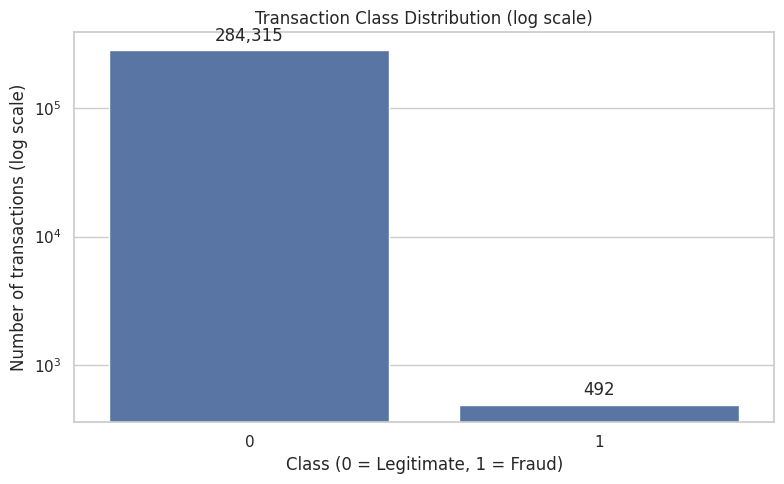

In [11]:
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x="Class", order=[0, 1])
ax.set_yscale("log")
ax.set_title("Transaction Class Distribution (log scale)")
ax.set_xlabel("Class (0 = Legitimate, 1 = Fraud)")
ax.set_ylabel("Number of transactions (log scale)")
for patch, class_value in zip(ax.patches, [0, 1]):
    count = int(class_counts.get(class_value, 0))
    ax.annotate(f"{count:,}", (patch.get_x() + patch.get_width() / 2, patch.get_height()),
                ha="center", va="bottom", xytext=(0, 4), textcoords="offset points")
plt.tight_layout()
plt.show()

### Overall feature correlations

<Axes: >

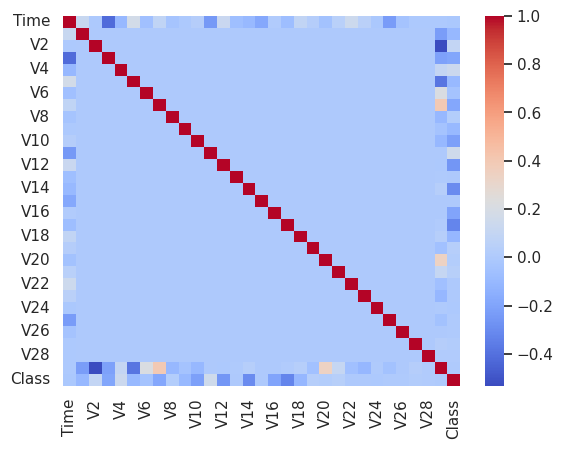

In [12]:
sns.heatmap(df.corr(), cmap='coolwarm')

### `Time` versus `Amount`: all transactions

<Axes: xlabel='Time', ylabel='Amount'>

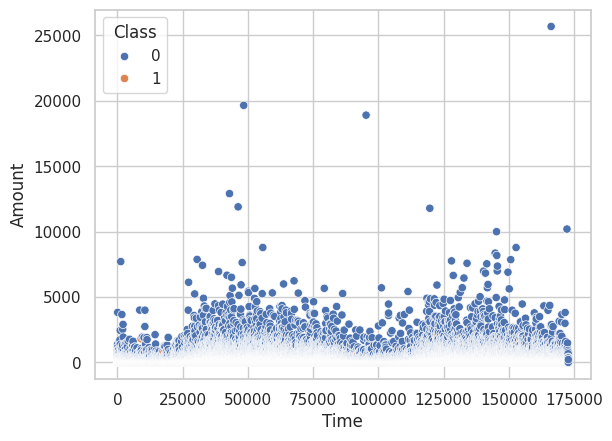

In [13]:
sns.scatterplot(x=df['Time'], y=df['Amount'], hue=df['Class'])

### Fraudulent transactions only (Class 1)

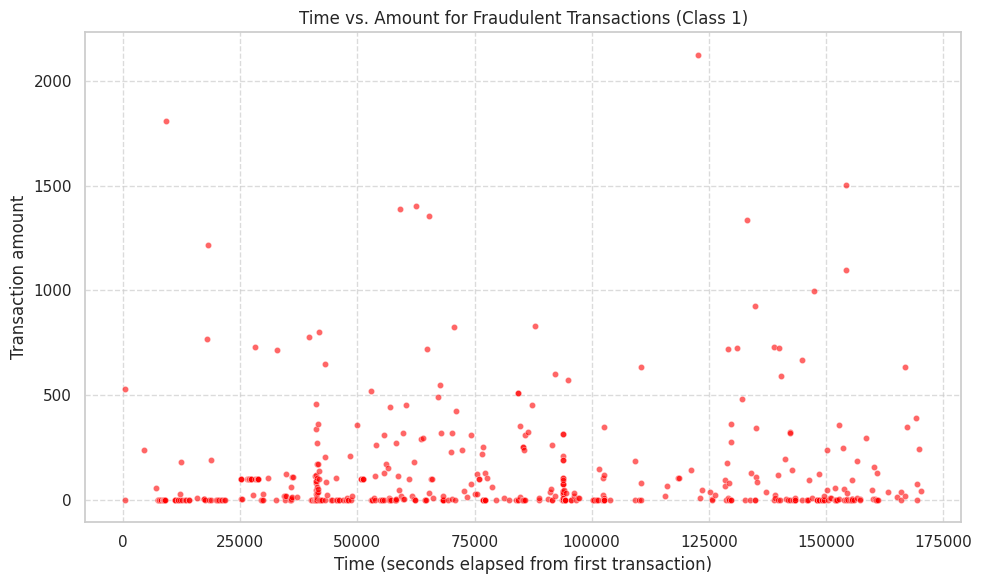

In [14]:
fraud_transactions = df[df['Class'] == 1]

plt.figure(figsize=(10, 6))
sns.scatterplot(x=fraud_transactions['Time'], y=fraud_transactions['Amount'], color='red', s=20, alpha=0.6)
plt.title('Time vs. Amount for Fraudulent Transactions (Class 1)')
plt.xlabel('Time (seconds elapsed from first transaction)')
plt.ylabel('Transaction amount')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Legitimate transactions only (Class 0)

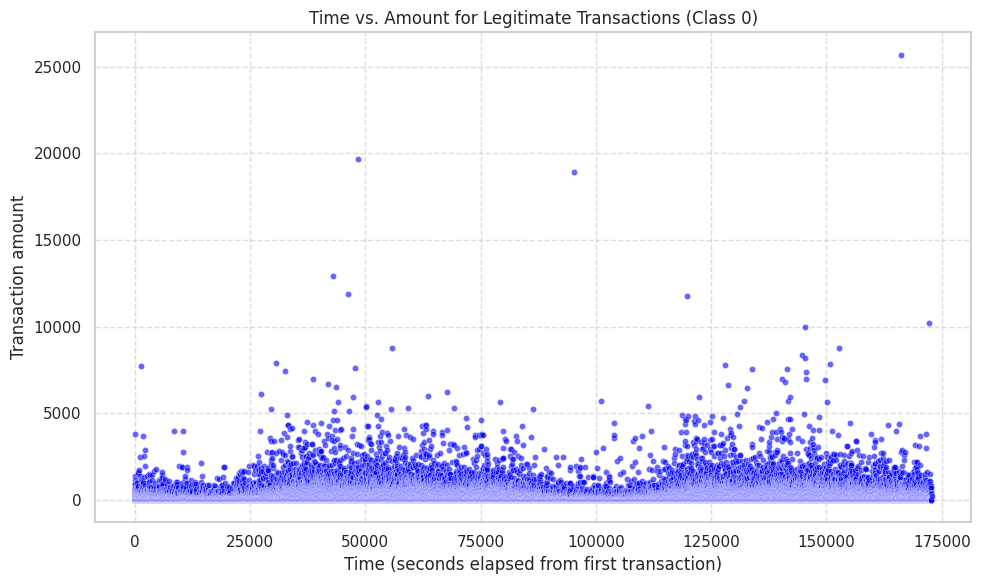

In [15]:
legit_transactions = df[df['Class'] == 0]

plt.figure(figsize=(10, 6))
sns.scatterplot(x=legit_transactions['Time'], y=legit_transactions['Amount'], color='blue', s=20, alpha=0.6)
plt.title('Time vs. Amount for Legitimate Transactions (Class 0)')
plt.xlabel('Time (seconds elapsed from first transaction)')
plt.ylabel('Transaction amount')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Timing of fraudulent transactions

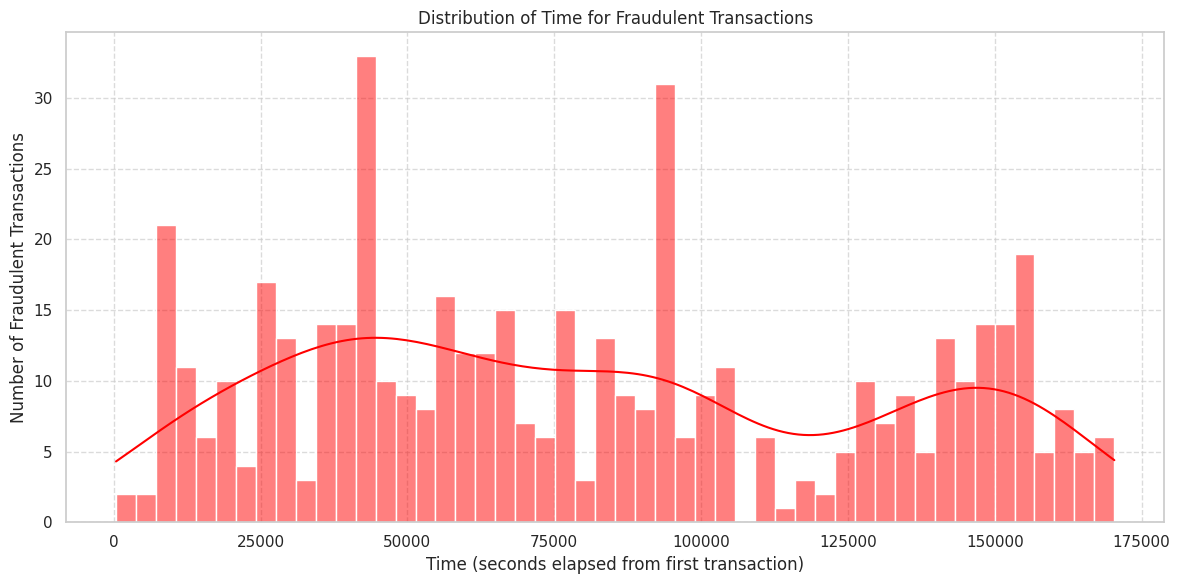

In [16]:
plt.figure(figsize=(12, 6))
sns.histplot(fraud_transactions['Time'], bins=50, kde=True, color='red')
plt.title('Distribution of Time for Fraudulent Transactions')
plt.xlabel('Time (seconds elapsed from first transaction)')
plt.ylabel('Number of Fraudulent Transactions')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Feature correlations within each class

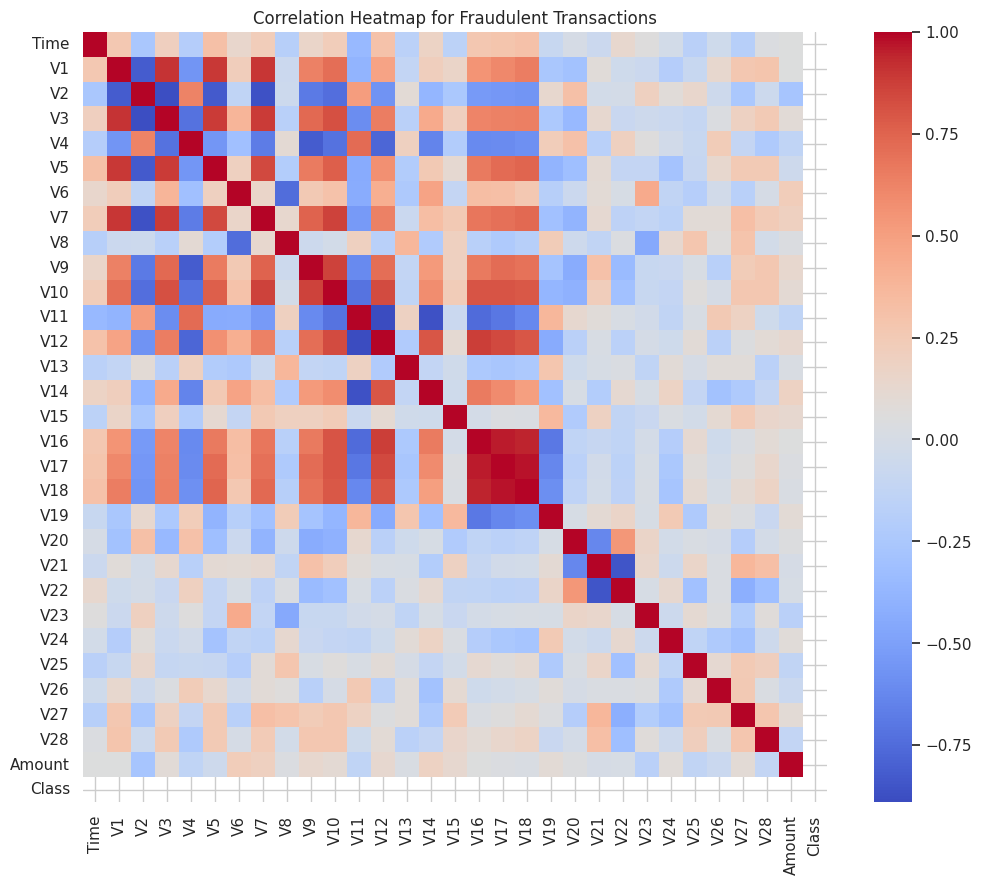

In [17]:
plt.figure(figsize=(12, 10))
sns.heatmap(fraud_transactions.corr(), cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap for Fraudulent Transactions')
plt.show()

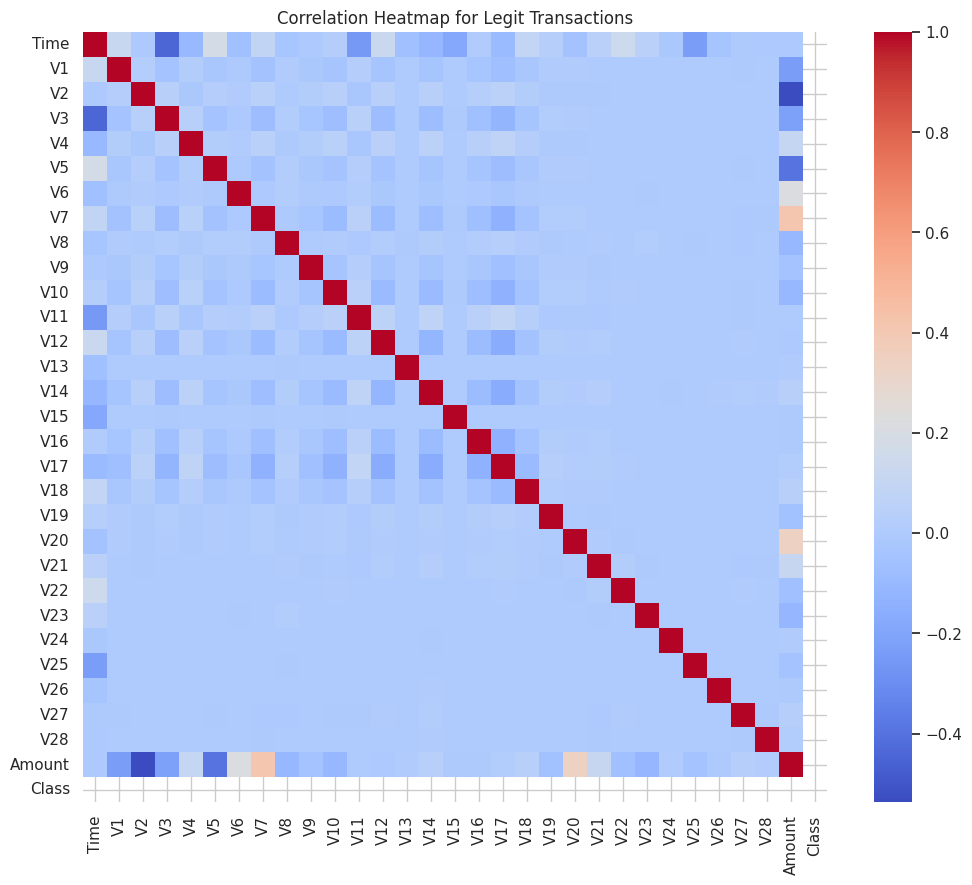

In [18]:
plt.figure(figsize=(12, 10))
sns.heatmap(legit_transactions.corr(), cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap for Legit Transactions')
plt.show()

### How to discuss the EDA in an interview

- The class-count view establishes why overall accuracy alone is not enough.
- The combined scatter plot gives a broad view of transaction time and amount; the separate plots make the much more common legitimate class easier to inspect independently.
- The fraud-time histogram checks whether fraud observations are spread uniformly over the recorded time range or clustered in particular periods.
- The two class-specific heatmaps are exploratory, not proof of causation. Correlation alone is not enough to judge whether a feature is useful for classification.
- `V1`–`V28` are anonymized transformed variables, so the plots do not support a domain interpretation of each individual component.

## 4. Feature engineering and train/test split

We separate the target, apply `log1p` to `Amount`, and remove the raw `Amount` column from the model features. The train/test split is stratified so the rare fraud class remains represented at a similar proportion in both sets.

**Important:** the test set remains untouched by resampling. Every model is evaluated on the same held-out test rows with their original class distribution.

In [19]:
X = df.drop(columns=["Class"]).copy()
y = df["Class"].astype(int).copy()

X["Amount_log"] = np.log1p(X["Amount"])
X.drop(columns=["Amount"], inplace=True)

print(f"Model feature matrix: {X.shape}")
print(f"Target vector: {y.shape}")
X.head()

Model feature matrix: (284807, 30)
Target vector: (284807,)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount_log
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,5.014760
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,1.305626
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,5.939276
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,4.824306
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,4.262539


In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Training rows: {len(X_train):,}")
print(f"Test rows:     {len(X_test):,}")
print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True).sort_index().rename(index={0: "Legitimate", 1: "Fraud"}))
print("\nTest class proportions:")
print(y_test.value_counts(normalize=True).sort_index().rename(index={0: "Legitimate", 1: "Fraud"}))

Training rows: 227,845
Test rows:     56,962

Training class proportions:
Class
Legitimate    0.998271
Fraud         0.001729
Name: proportion, dtype: float64

Test class proportions:
Class
Legitimate    0.99828
Fraud         0.00172
Name: proportion, dtype: float64


### Preprocessing

`Time`, `Amount_log`, and the anonymized numeric components are standardized inside a preprocessing object. Fitting the preprocessor inside each model pipeline means it learns its scaling values from the training split only. Scaling is not usually necessary for Random Forest itself, but it is important for distance-based SMOTE and useful for Logistic Regression, so the same preprocessing definition can be applied consistently.

In [21]:
feature_columns = X.columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[("standardize", StandardScaler(), feature_columns)],
    remainder="drop",
)

## 5. Models I am comparing

Now that the preprocessing is defined, I am comparing four approaches on the same training data:

- Logistic Regression as my baseline
- Random Forest trained on the original class distribution
- Random Forest with `balanced_subsample`
- Random Forest with default SMOTE

I am using 5-fold stratified cross-validation so each model is checked on different folds while keeping the fraud proportion similar. I will use these training results to compare the models and choose a threshold. I will leave `X_test` and `y_test` alone until the final evaluation.

### Set up cross-validation and the candidate models

I am using the same folds for every candidate so the comparison is more consistent. SMOTE is inside an `ImbPipeline`, which means it is applied only to the training fold each time. The validation fold keeps the original fraud proportion.

In [22]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

# Baseline: Logistic Regression
logistic_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    (
        "classifier",
        LogisticRegression(
            solver="liblinear",
            max_iter=1000,
            random_state=RANDOM_STATE,
        ),
    ),
])

# Random Forest trained on the original class distribution
rf_original = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    (
        "classifier",
        RandomForestClassifier(
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
    ),
])

# Random Forest with class weights adjusted for each bootstrap sample
rf_balanced_subsample = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    (
        "classifier",
        RandomForestClassifier(
            class_weight="balanced_subsample",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
    ),
])

# Random Forest with default SMOTE. For binary classification, "auto"
# resamples the training fold until the two classes are balanced.
rf_smote = ImbPipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("smote", SMOTE(sampling_strategy="auto", random_state=RANDOM_STATE)),
    (
        "classifier",
        RandomForestClassifier(
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
    ),
])

candidate_models = {
    "Logistic Regression baseline": logistic_model,
    "Random Forest — original distribution": rf_original,
    "Random Forest — balanced_subsample": rf_balanced_subsample,
    "Random Forest — SMOTE default (auto)": rf_smote,
}

print(f"Number of candidate models: {len(candidate_models)}")

Number of candidate models: 4


### Get cross-validation results and out-of-fold probabilities

For the first comparison, I am looking at precision, recall and F1 at the usual `0.50` threshold, along with ROC-AUC and Average Precision. Average Precision is especially useful here because fraud is a very small part of the dataset.

I am also saving an out-of-fold probability for every row in `X_train`. Each row's probability comes from a model that did not train on that row. I will use these scores for threshold selection below. The scores in this section are for model selection; the final test results will be reported separately.

In [23]:
def run_cv_and_get_oof(estimator, X, y, cv_strategy):
    """Return out-of-fold fraud probabilities and per-fold metrics."""
    y_array = np.asarray(y).ravel()
    oof_scores = np.full(len(y_array), np.nan)
    fold_rows = []

    for fold, (train_idx, val_idx) in enumerate(
        cv_strategy.split(X, y_array),
        start=1,
    ):
        X_fold_train = X.iloc[train_idx]
        X_fold_val = X.iloc[val_idx]
        y_fold_train = y_array[train_idx]
        y_fold_val = y_array[val_idx]

        # A fresh pipeline is fitted within each fold.
        fold_model = clone(estimator)
        fold_model.fit(X_fold_train, y_fold_train)

        fold_scores = fold_model.predict_proba(X_fold_val)[:, 1]
        oof_scores[val_idx] = fold_scores

        # Metrics at threshold 0.50 for the baseline comparison.
        fold_pred = (fold_scores >= 0.50).astype(int)
        fold_rows.append({
            "Fold": fold,
            "Precision @ 0.50": precision_score(
                y_fold_val, fold_pred, zero_division=0
            ),
            "Recall @ 0.50": recall_score(
                y_fold_val, fold_pred, zero_division=0
            ),
            "F1 @ 0.50": f1_score(
                y_fold_val, fold_pred, zero_division=0
            ),
            "ROC-AUC": roc_auc_score(y_fold_val, fold_scores),
            "Average Precision": average_precision_score(
                y_fold_val, fold_scores
            ),
        })

    if np.isnan(oof_scores).any():
        raise RuntimeError("Some training rows did not receive an OOF prediction.")

    return oof_scores, pd.DataFrame(fold_rows)

In [24]:
oof_scores_by_model = {}
cv_summary_rows = []

for model_name, estimator in candidate_models.items():
    print(f"Running 5-fold CV: {model_name}")

    oof_scores, fold_results = run_cv_and_get_oof(
        estimator=estimator,
        X=X_train,
        y=y_train,
        cv_strategy=cv_strategy,
    )
    oof_scores_by_model[model_name] = oof_scores

    summary_row = {"Model": model_name}
    for metric in [
        "Precision @ 0.50",
        "Recall @ 0.50",
        "F1 @ 0.50",
        "ROC-AUC",
        "Average Precision",
    ]:
        summary_row[f"{metric} mean"] = fold_results[metric].mean()
        summary_row[f"{metric} std"] = fold_results[metric].std(ddof=1)

    cv_summary_rows.append(summary_row)

cv_summary = (
    pd.DataFrame(cv_summary_rows)
    .sort_values("Average Precision mean", ascending=False)
    .reset_index(drop=True)
)

display(cv_summary.round(4))

Running 5-fold CV: Logistic Regression baseline
Running 5-fold CV: Random Forest — original distribution


/usr/local/lib/python3.13/dist-packages/treelite/core.py:25: UserWarning: [06:19:57] /__w/nvforest/nvforest/python/nvforest/build/cp311-abi3-linux_x86_64/_deps/treelite-src/src/serializer.cc:202: The model you are loading originated from a newer Treelite version; some functionalities may be unavailable.
Currently running Treelite version 4.6.1
The model checkpoint was generated from Treelite version 4.7.2
  warnings.warn(py_str(msg))
/usr/local/lib/python3.13/dist-packages/treelite/core.py:25: UserWarning: [06:19:59] /__w/nvforest/nvforest/python/nvforest/build/cp311-abi3-linux_x86_64/_deps/treelite-src/src/serializer.cc:202: The model you are loading originated from a newer Treelite version; some functionalities may be unavailable.
Currently running Treelite version 4.6.1
The model checkpoint was generated from Treelite version 4.7.2
  warnings.warn(py_str(msg))
/usr/local/lib/python3.13/dist-packages/treelite/core.py:25: UserWarning: [06:20:01] /__w/nvforest/nvforest/python/nvforest/

Running 5-fold CV: Random Forest — balanced_subsample
Running 5-fold CV: Random Forest — SMOTE default (auto)


/usr/local/lib/python3.13/dist-packages/treelite/core.py:25: UserWarning: [06:26:55] /__w/nvforest/nvforest/python/nvforest/build/cp311-abi3-linux_x86_64/_deps/treelite-src/src/serializer.cc:202: The model you are loading originated from a newer Treelite version; some functionalities may be unavailable.
Currently running Treelite version 4.6.1
The model checkpoint was generated from Treelite version 4.7.2
  warnings.warn(py_str(msg))
/usr/local/lib/python3.13/dist-packages/treelite/core.py:25: UserWarning: [06:26:58] /__w/nvforest/nvforest/python/nvforest/build/cp311-abi3-linux_x86_64/_deps/treelite-src/src/serializer.cc:202: The model you are loading originated from a newer Treelite version; some functionalities may be unavailable.
Currently running Treelite version 4.6.1
The model checkpoint was generated from Treelite version 4.7.2
  warnings.warn(py_str(msg))
/usr/local/lib/python3.13/dist-packages/treelite/core.py:25: UserWarning: [06:27:00] /__w/nvforest/nvforest/python/nvforest/

,Model,Precision @ 0.50 mean,Precision @ 0.50 std,Recall @ 0.50 mean,Recall @ 0.50 std,F1 @ 0.50 mean,F1 @ 0.50 std,ROC-AUC mean,ROC-AUC std,Average Precision mean,Average Precision std
0,Random Forest — original distribution,0.9449,0.0255,0.7715,0.0317,0.8489,0.0183,0.9486,0.0192,0.8405,0.0289
1,Random Forest — SMOTE default (auto),0.8765,0.0261,0.7995,0.0589,0.8347,0.0261,0.9748,0.0172,0.8382,0.0255
2,Random Forest — balanced_subsample,0.9470,0.0255,0.7512,0.0344,0.8371,0.0147,0.9465,0.0189,0.8358,0.0227
3,Logistic Regression baseline,0.8804,0.0413,0.6395,0.0355,0.7398,0.0218,0.9770,0.0135,0.7612,0.0457


## 6. Choose a threshold for each model

A threshold of `0.50` is only the default decision rule. Since missing a fraudulent transaction matters in this project, I am checking other thresholds too.

For now, my target is at least **90% fraud precision** and **more than 80% fraud recall**. I first look for the highest recall while keeping precision at or above 90%. If a model cannot reach that precision, I keep its best-F1 threshold for comparison and mark it as not meeting the precision target. These results help me select a configuration; they are not my final test results.

In [25]:
TARGET_PRECISION = 0.90
TARGET_RECALL = 0.75  # Recall must be strictly greater than this value.

threshold_rows = []

for model_name, oof_scores in oof_scores_by_model.items():
    precision_curve, recall_curve, thresholds = precision_recall_curve(
        y_train,
        oof_scores,
    )

    # The last precision/recall point has no corresponding threshold.
    precision_at_thresholds = precision_curve[:-1]
    recall_at_thresholds = recall_curve[:-1]

    valid_indices = np.flatnonzero(
        precision_at_thresholds >= TARGET_PRECISION
    )

    if len(valid_indices) > 0:
        # Among thresholds meeting the precision target, maximize recall.
        max_recall = recall_at_thresholds[valid_indices].max()
        tied_indices = valid_indices[
            np.isclose(recall_at_thresholds[valid_indices], max_recall)
        ]
        best_idx = tied_indices[
            np.argmax(precision_at_thresholds[tied_indices])
        ]
        selection_basis = "Max recall with precision constraint"
    else:
        # This fallback is for comparison only; it does not meet the
        # precision target by definition.
        curve_f1 = (
            2 * precision_at_thresholds * recall_at_thresholds
            / np.maximum(precision_at_thresholds + recall_at_thresholds, 1e-12)
        )
        best_idx = int(np.argmax(curve_f1))
        selection_basis = "Fallback: highest F1; precision target unavailable"

    best_threshold = float(thresholds[best_idx])
    y_oof_pred = (oof_scores >= best_threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_train, y_oof_pred, labels=[0, 1]
    ).ravel()

    actual_precision = precision_score(y_train, y_oof_pred, zero_division=0)
    actual_recall = recall_score(y_train, y_oof_pred, zero_division=0)
    actual_f1 = f1_score(y_train, y_oof_pred, zero_division=0)

    threshold_rows.append({
        "Model": model_name,
        "Threshold": best_threshold,
        "Fraud precision": actual_precision,
        "Fraud recall": actual_recall,
        "Fraud F1": actual_f1,
        "Average Precision": average_precision_score(y_train, oof_scores),
        "False positives": int(fp),
        "Missed frauds (FN)": int(fn),
        "True negatives (TN)": int(tn),
        "True fraud detections (TP)": int(tp),
        "Meets precision target": actual_precision >= TARGET_PRECISION,
        "Meets recall target": actual_recall > TARGET_RECALL,
        "Meets both targets": (
            actual_precision >= TARGET_PRECISION
            and actual_recall > TARGET_RECALL
        ),
        "Selection basis": selection_basis,
    })

threshold_summary = pd.DataFrame(threshold_rows)
threshold_summary = threshold_summary.sort_values(
    [
        "Meets both targets",
        "Meets precision target",
        "Fraud recall",
        "Fraud precision",
        "False positives",
    ],
    ascending=[False, False, False, False, True],
).reset_index(drop=True)

display(threshold_summary.style.format({
    "Threshold": "{:.4f}",
    "Fraud precision": "{:.4f}",
    "Fraud recall": "{:.4f}",
    "Fraud F1": "{:.4f}",
    "Average Precision": "{:.4f}",
}))

,Model,Threshold,Fraud precision,Fraud recall,Fraud F1,Average Precision,False positives,Missed frauds (FN),True negatives (TN),True fraud detections (TP),Meets precision target,Meets recall target,Meets both targets,Selection basis
0,Random Forest — original distribution,0.3600,0.9117,0.8122,0.8591,0.8400,31,74,227420,320,True,True,True,Max recall with precision constraint
1,Random Forest — balanced_subsample,0.2500,0.9046,0.7944,0.8459,0.8361,33,81,227418,313,True,False,False,Max recall with precision constraint
2,Random Forest — SMOTE default (auto),0.6200,0.9000,0.7766,0.8338,0.8379,34,88,227417,306,True,False,False,Max recall with precision constraint
3,Logistic Regression baseline,0.6898,0.9000,0.5939,0.7156,0.7605,26,160,227425,234,True,False,False,Max recall with precision constraint


### Select one model and its threshold

I want to finish with one model, not keep several models as the final answer. I select the model with the highest recall among the candidates that meet both targets. If none meet both, I choose the best available option under the precision target and clearly note that recall is below target. If no model reaches the precision target, I use F1 as a fallback for further inspection.

I will make this choice using the training cross-validation results only. I will not change it based on the test results.

In [26]:
qualified = threshold_summary[threshold_summary["Meets both targets"]]
precision_eligible = threshold_summary[threshold_summary["Meets precision target"]]

if not qualified.empty:
    eligible_models = qualified.sort_values(
        ["Fraud recall", "Fraud precision", "False positives", "Average Precision"],
        ascending=[False, False, True, False],
    )
    best_candidate = eligible_models.iloc[0]
    selection_status = "Meets both precision and recall targets"

elif not precision_eligible.empty:
    eligible_models = precision_eligible.sort_values(
        ["Fraud recall", "Fraud precision", "False positives"],
        ascending=[False, False, True],
    )
    best_candidate = eligible_models.iloc[0]
    selection_status = "Meets precision target, but not recall target"

else:
    eligible_models = threshold_summary.sort_values(
        ["Fraud F1", "Fraud precision", "Fraud recall"],
        ascending=[False, False, False],
    )
    best_candidate = eligible_models.iloc[0]
    selection_status = "Fallback selection; precision target not met"

best_model_name = best_candidate["Model"]
best_threshold = float(best_candidate["Threshold"])

print("Selected model:", best_model_name)
print(f"Selected threshold: {best_threshold:.4f}")
print("Selection status:", selection_status)
print(f"OOF fraud precision: {best_candidate['Fraud precision']:.4f}")
print(f"OOF fraud recall:    {best_candidate['Fraud recall']:.4f}")

Selected model: Random Forest — original distribution
Selected threshold: 0.3600
Selection status: Meets both precision and recall targets
OOF fraud precision: 0.9117
OOF fraud recall:    0.8122


## 7. Final evaluation on the test set

After choosing the model and threshold, I fit that model again on all of `X_train`. I then evaluate it on `X_test` and `y_test` once. The model is now trained on more rows than each fold model, so its probability scores can be slightly different; I will keep the threshold selected above fixed rather than tune it using the test set.

In [27]:
# Fit the selected pipeline on all of the training data.
final_model = clone(candidate_models[best_model_name])
final_model.fit(X_train, y_train)

# Apply the threshold chosen from out-of-fold training predictions.
y_test_scores = final_model.predict_proba(X_test)[:, 1]
y_test_pred = (y_test_scores >= best_threshold).astype(int)

final_cm = confusion_matrix(y_test, y_test_pred, labels=[0, 1])
tn, fp, fn, tp = final_cm.ravel()

test_precision = precision_score(y_test, y_test_pred, zero_division=0)
test_recall = recall_score(y_test, y_test_pred, zero_division=0)
test_f1 = f1_score(y_test, y_test_pred, zero_division=0)
test_roc_auc = roc_auc_score(y_test, y_test_scores)
test_average_precision = average_precision_score(y_test, y_test_scores)

print("Final model:", best_model_name)
print(f"Fixed threshold: {best_threshold:.4f}")
print("\nClassification report:")
print(classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1],
    target_names=["Legitimate", "Fraud"],
    digits=4,
    zero_division=0,
))

print(f"ROC-AUC: {test_roc_auc:.4f}")
print(f"Average Precision: {test_average_precision:.4f}")
print(f"False positives: {fp:,}")
print(f"Missed frauds (FN): {fn:,}")
print(f"True negatives (TN): {tn:,}")
print(f"True fraud detections (TP): {tp:,}")

final_test_summary = pd.DataFrame([{
    "Model": best_model_name,
    "Threshold": best_threshold,
    "Fraud precision": test_precision,
    "Fraud recall": test_recall,
    "Fraud F1": test_f1,
    "ROC-AUC": test_roc_auc,
    "Average Precision": test_average_precision,
    "False positives": int(fp),
    "Missed frauds (FN)": int(fn),
    "True negatives (TN)": int(tn),
    "True fraud detections (TP)": int(tp),
    "Meets precision target": test_precision >= TARGET_PRECISION,
    "Meets recall target": test_recall > TARGET_RECALL,
}])

display(final_test_summary.round(4))

Final model: Random Forest — original distribution
Fixed threshold: 0.3600

Classification report:
              precision    recall  f1-score   support

  Legitimate     0.9997    0.9999    0.9998     56864
       Fraud     0.9318    0.8367    0.8817        98

    accuracy                         0.9996     56962
   macro avg     0.9658    0.9183    0.9408     56962
weighted avg     0.9996    0.9996    0.9996     56962

ROC-AUC: 0.9474
Average Precision: 0.8793
False positives: 6
Missed frauds (FN): 16
True negatives (TN): 56,858
True fraud detections (TP): 82


/usr/local/lib/python3.13/dist-packages/treelite/core.py:25: UserWarning: [06:27:09] /__w/nvforest/nvforest/python/nvforest/build/cp311-abi3-linux_x86_64/_deps/treelite-src/src/serializer.cc:202: The model you are loading originated from a newer Treelite version; some functionalities may be unavailable.
Currently running Treelite version 4.6.1
The model checkpoint was generated from Treelite version 4.7.2
  warnings.warn(py_str(msg))


,Model,Threshold,Fraud precision,Fraud recall,Fraud F1,ROC-AUC,Average Precision,False positives,Missed frauds (FN),True negatives (TN),True fraud detections (TP),Meets precision target,Meets recall target
0,Random Forest — original distribution,0.36,0.9318,0.8367,0.8817,0.9474,0.8793,6,16,56858,82,True,True


## 8. Graphs for the model comparison

I added these plots to make the comparison easier to read. The first two use cross-validation results and out-of-fold probabilities from `X_train`. The last plots summarize the selected model's threshold and final test predictions.

### Average Precision across the five folds

I use the mean Average Precision to compare how well the candidate models rank fraud cases, and show the standard deviation across folds to see how much the score changes between folds.

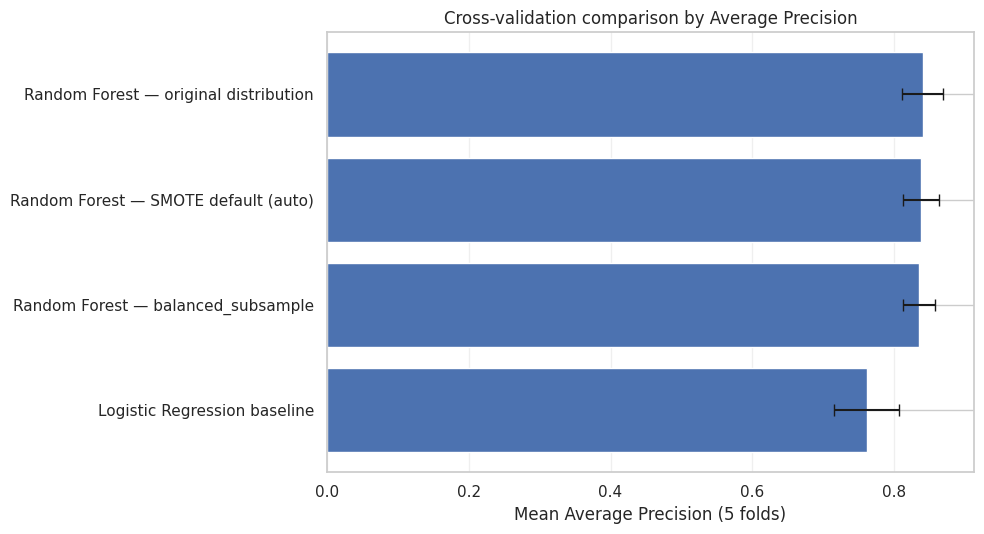

In [28]:
plot_data = cv_summary.sort_values("Average Precision mean", ascending=True).copy()

fig, ax = plt.subplots(figsize=(10, 5.5))
y_positions = np.arange(len(plot_data))
ax.barh(
    y_positions,
    plot_data["Average Precision mean"],
    xerr=plot_data["Average Precision std"],
    capsize=4,
)
ax.set_yticks(y_positions)
ax.set_yticklabels(plot_data["Model"])
ax.set_xlabel("Mean Average Precision (5 folds)")
ax.set_title("Cross-validation comparison by Average Precision")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
plt.show()

### Precision–recall curves from out-of-fold predictions

This shows the precision–recall trade-off for each model across thresholds. The dashed lines mark the targets I used for selection. Curves here are for comparing models on the training data; the final performance is shown separately below.

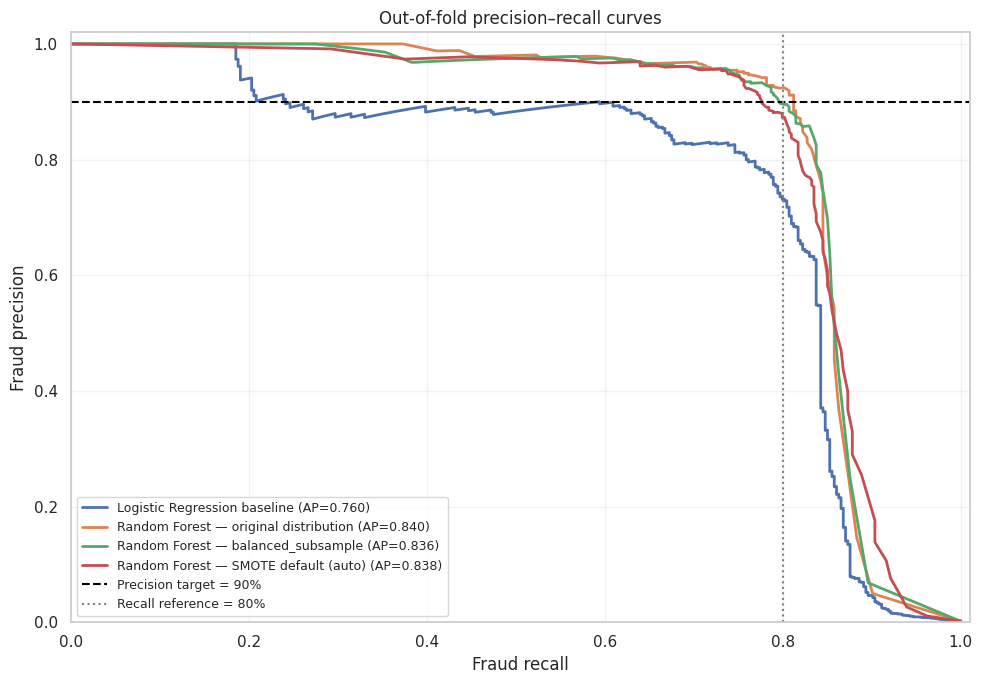

In [29]:
fig, ax = plt.subplots(figsize=(10, 7))

for model_name, oof_scores in oof_scores_by_model.items():
    precision_curve, recall_curve, _ = precision_recall_curve(y_train, oof_scores)
    ap = average_precision_score(y_train, oof_scores)
    ax.plot(
        recall_curve,
        precision_curve,
        linewidth=2,
        label=f"{model_name} (AP={ap:.3f})",
    )

ax.axhline(
    TARGET_PRECISION,
    color="black",
    linestyle="--",
    label=f"Precision target = {TARGET_PRECISION:.0%}",
)
ax.axvline(
    TARGET_RECALL,
    color="gray",
    linestyle=":",
    label=f"Recall reference = {TARGET_RECALL:.0%}",
)
ax.set_xlabel("Fraud recall")
ax.set_ylabel("Fraud precision")
ax.set_title("Out-of-fold precision–recall curves")
ax.set_xlim(0, 1.01)
ax.set_ylim(0, 1.02)
ax.legend(loc="best", fontsize=9)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

### Precision and recall at different thresholds for the selected model

I also plot how precision and recall change with the threshold for the selected model. The vertical line is the threshold chosen from the out-of-fold predictions. This helps explain why I did not automatically keep the default threshold of `0.50`.

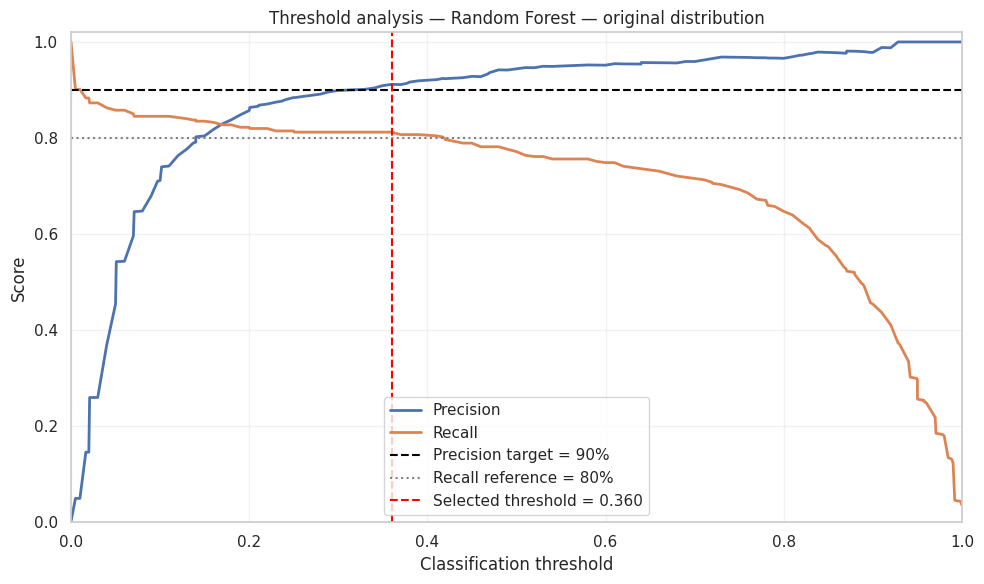

In [30]:
selected_oof_scores = oof_scores_by_model[best_model_name]
precision_curve, recall_curve, thresholds = precision_recall_curve(
    y_train,
    selected_oof_scores,
)

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(thresholds, precision_curve[:-1], label="Precision", linewidth=2)
ax.plot(thresholds, recall_curve[:-1], label="Recall", linewidth=2)
ax.axhline(
    TARGET_PRECISION,
    color="black",
    linestyle="--",
    label=f"Precision target = {TARGET_PRECISION:.0%}",
)
ax.axhline(
    TARGET_RECALL,
    color="gray",
    linestyle=":",
    label=f"Recall reference = {TARGET_RECALL:.0%}",
)
ax.axvline(
    best_threshold,
    color="red",
    linestyle="--",
    label=f"Selected threshold = {best_threshold:.3f}",
)
ax.set_xlabel("Classification threshold")
ax.set_ylabel("Score")
ax.set_title(f"Threshold analysis — {best_model_name}")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(loc="best")
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

### Confusion matrix on the final test set

The confusion matrix shows the final errors on the original, imbalanced test set. False negatives are fraudulent transactions that the model missed, while false positives are legitimate transactions flagged for review.

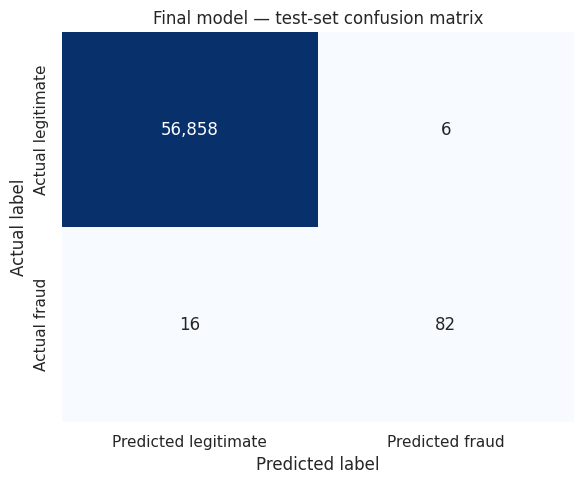

In [31]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    final_cm,
    annot=True,
    fmt=",d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Predicted legitimate", "Predicted fraud"],
    yticklabels=["Actual legitimate", "Actual fraud"],
    ax=ax,
)
ax.set_title("Final model — test-set confusion matrix")
ax.set_xlabel("Predicted label")
ax.set_ylabel("Actual label")
fig.tight_layout()
plt.show()

### What I take from the results

I will use the final test metrics to report how the selected model performed on unseen transactions. If its precision or recall is below my target on the test set, I will report that rather than changing the threshold after seeing the result. The cross-validation and threshold plots explain how I made the selection; the final test evaluation is the separate check.